<a href="https://colab.research.google.com/github/ramosnova977-droid/big-data/blob/main/02_Big_Data_MapReduce_Civil_Comments_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import zipfile

ruta_zip = "/content/drive/MyDrive/train.csv.zip"

print("Archivo encontrado:", os.path.exists(ruta_zip))

with zipfile.ZipFile(ruta_zip, "r") as archivo:
    print(archivo.namelist())

Archivo encontrado: True
['train.csv']


In [3]:
import pandas as pd
import zipfile

columnas = [
    "id",
    "comment_text",
    "target",
    "created_date",
    "publication_id",
    "rating"
]

with zipfile.ZipFile(ruta_zip, "r") as archivo:
    with archivo.open("train.csv") as csv:
        df_bigdata = pd.read_csv(
            csv,
            usecols=columnas,
            nrows=10000
        )

print("Dimensiones:", df_bigdata.shape)
print("\nValores nulos:")
print(df_bigdata.isnull().sum())

display(df_bigdata.head())

Dimensiones: (10000, 6)

Valores nulos:
id                0
target            0
comment_text      0
created_date      0
publication_id    0
rating            0
dtype: int64


,id,target,comment_text,created_date,publication_id,rating
0,59848,0.000000,"This is so cool. It's like, 'would you want yo...",2015-09-29 10:50:41.987077+00,2,rejected
1,59849,0.000000,Thank you!! This would make my life a lot less...,2015-09-29 10:50:42.870083+00,2,rejected
2,59852,0.000000,This is such an urgent design problem; kudos t...,2015-09-29 10:50:45.222647+00,2,rejected
3,59855,0.000000,Is this something I'll be able to install on m...,2015-09-29 10:50:47.601894+00,2,rejected
4,59856,0.893617,haha you guys are a bunch of losers.,2015-09-29 10:50:48.488476+00,2,rejected


In [4]:
import numpy as np

df_bigdata["clasificacion"] = np.select(
    [
        df_bigdata["target"] >= 0.5,
        df_bigdata["target"] < 0.5
    ],
    [
        "toxico",
        "no_toxico"
    ],
    default="desconocido"
)

print(df_bigdata["clasificacion"].value_counts())

clasificacion
no_toxico    9422
toxico        578
Name: count, dtype: int64


In [5]:
# Preparación del archivo para Hadoop

ruta_hadoop = "/content/civil_comments_10k.jsonl"

df_bigdata.to_json(
    ruta_hadoop,
    orient="records",
    lines=True,
    force_ascii=False
)

print("Archivo generado correctamente")
print("Ruta:", ruta_hadoop)
print("Registros:", len(df_bigdata))
print("Tamaño en MB:", round(
    os.path.getsize(ruta_hadoop) / 1024**2, 2
))

Archivo generado correctamente
Ruta: /content/civil_comments_10k.jsonl
Registros: 10000
Tamaño en MB: 4.93


In [6]:
import json

with open(ruta_hadoop, "r", encoding="utf-8") as archivo:
    primer_registro = json.loads(archivo.readline())

print(json.dumps(
    primer_registro,
    indent=4,
    ensure_ascii=False
))

{
    "id": 59848,
    "target": 0.0,
    "comment_text": "This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!",
    "created_date": "2015-09-29 10:50:41.987077+00",
    "publication_id": 2,
    "rating": "rejected",
    "clasificacion": "no_toxico"
}


In [7]:
%%bash
set -e

apt-get update -qq
apt-get install -y -qq openjdk-11-jdk-headless

wget -q --show-progress \
https://downloads.apache.org/hadoop/common/hadoop-3.4.3/hadoop-3.4.3.tar.gz \
-O /content/hadoop.tar.gz

tar -xzf /content/hadoop.tar.gz -C /content

echo "Instalacion completada"

Selecting previously unselected package openjdk-11-jre-headless:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../openjdk-11-jre-headless_11.0.33.1+1-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jre-headless:amd64 (11.0.33.1+1-1ubuntu1~24.04.1) ...
Selecting previously unselected package openjdk-11-jdk-headless:amd64.
Preparing to unpack .../openjdk-11-jdk-headless_11.0.33.1+1-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jdk-headless:amd64 (11.0.33.1+1-1ubuntu1~24.04.1) ...
Setting up openjdk-11-jre-headless:amd64 (11.0.33.1+1-1ubuntu1~24.04.1) ...
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/jjs to provide /usr/bin/jjs (jjs) in auto mode
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/rmid to provide /usr/bin/rmid (rmid) in auto mode
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/pack200 to provide /usr/bin/pack200 (pack200) in auto mode
update-alternatives: us

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)

     0K .......... .......... .......... .......... ..........  0%  268K 31m19s
    50K .......... .......... .......... .......... ..........  0% 1.21M 19m2s
   100K .......... .......... .......... .......... ..........  0%  858K 15m57s
   150K .......... .......... .......... .......... ..........  0% 8.85M 12m11s
   200K .......... .......... .......... .......... ..........  0%  594K 12m34s
   250K .......... .......... .......... .......... ..........  0% 14.1M 10m34s
   300K .......... .......... .......... .......... ..........  0% 21.4M 9m7s
   350K .......... .......... .......... .......... ..........  0% 14.7M 8m3s
   400K .......... .......... .......... .......... ..........  0% 1.47M 7m46s
   450K .......... .......... .......... .......... ..........  0%  979K 7m51s
   500K .........

In [8]:
import os
import glob

os.environ["JAVA_HOME"] = glob.glob(
    "/usr/lib/jvm/java-11-openjdk-*"
)[0]

os.environ["HADOOP_HOME"] = "/content/hadoop-3.4.3"

os.environ["PATH"] += (
    ":/content/hadoop-3.4.3/bin"
    ":/content/hadoop-3.4.3/sbin"
)

print("Variables configuradas")

Variables configuradas


In [9]:
!java -version
!hadoop version

[0.014s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.014s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
Hadoop 3.4.3
Source code repository https://github.com/apache/hadoop.git -r 9d50c6884666e794e45102260a4017bb31802e1b
Compiled by stevel on 2026-02-13T14:23Z
Compiled on platform linux-x86_64
Compiled with protoc 3.23.4
From source with checksum 2331238c4c2929e66645316a32a8613
This command was run using /content/hadoop-3.4.3/share/hadoop/common/hadoop-common-3.4.3.jar


In [10]:
import os
import glob

java11 = glob.glob("/usr/lib/jvm/java-11-openjdk-*")[0]

os.environ["JAVA_HOME"] = java11
os.environ["PATH"] = f"{java11}/bin:" + os.environ["PATH"]

print("JAVA_HOME:", os.environ["JAVA_HOME"])

!java -version
!hadoop version

JAVA_HOME: /usr/lib/jvm/java-11-openjdk-amd64
openjdk version "11.0.33.1" 2026-11-17
OpenJDK Runtime Environment (build 11.0.33.1+1-post-1ubuntu1-24.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 11.0.33.1+1-post-1ubuntu1-24.04.1-Ubuntu, mixed mode, sharing)
Hadoop 3.4.3
Source code repository https://github.com/apache/hadoop.git -r 9d50c6884666e794e45102260a4017bb31802e1b
Compiled by stevel on 2026-02-13T14:23Z
Compiled on platform linux-x86_64
Compiled with protoc 3.23.4
From source with checksum 2331238c4c2929e66645316a32a8613
This command was run using /content/hadoop-3.4.3/share/hadoop/common/hadoop-common-3.4.3.jar


In [11]:
import os
from pathlib import Path

hadoop = Path(os.environ["HADOOP_HOME"])
config = hadoop / "etc/hadoop"

# Configuracion de HDFS
(config / "core-site.xml").write_text("""
<configuration>
    <property>
        <name>fs.defaultFS</name>
        <value>hdfs://localhost:9000</value>
    </property>
</configuration>
""")

(config / "hdfs-site.xml").write_text("""
<configuration>
    <property>
        <name>dfs.replication</name>
        <value>1</value>
    </property>
    <property>
        <name>dfs.namenode.name.dir</name>
        <value>/content/hadoop-data/namenode</value>
    </property>
    <property>
        <name>dfs.datanode.data.dir</name>
        <value>/content/hadoop-data/datanode</value>
    </property>
</configuration>
""")

# Configuracion de MapReduce
(config / "mapred-site.xml").write_text("""
<configuration>
    <property>
        <name>mapreduce.framework.name</name>
        <value>yarn</value>
    </property>
    <property>
        <name>mapreduce.application.classpath</name>
        <value>$HADOOP_MAPRED_HOME/share/hadoop/mapreduce/*:$HADOOP_MAPRED_HOME/share/hadoop/mapreduce/lib/*</value>
    </property>
</configuration>
""")

# Configuracion de YARN
(config / "yarn-site.xml").write_text("""
<configuration>
    <property>
        <name>yarn.resourcemanager.hostname</name>
        <value>localhost</value>
    </property>
    <property>
        <name>yarn.nodemanager.aux-services</name>
        <value>mapreduce_shuffle</value>
    </property>
    <property>
        <name>yarn.nodemanager.env-whitelist</name>
        <value>JAVA_HOME,HADOOP_COMMON_HOME,HADOOP_HDFS_HOME,HADOOP_CONF_DIR,CLASSPATH_PREPEND_DISTCACHE,HADOOP_YARN_HOME,HADOOP_HOME,PATH,LANG,TZ,HADOOP_MAPRED_HOME</value>
    </property>
    <property>
        <name>yarn.nodemanager.resource.memory-mb</name>
        <value>4096</value>
    </property>
    <property>
        <name>yarn.scheduler.maximum-allocation-mb</name>
        <value>4096</value>
    </property>
</configuration>
""")

with open(config / "hadoop-env.sh", "a") as archivo:
    archivo.write(f'\nexport JAVA_HOME={os.environ["JAVA_HOME"]}\n')

print("Configuracion de Hadoop completada")

Configuracion de Hadoop completada


In [12]:
%%bash
set -e

# Inicializar HDFS solamente si es nuevo
if [ ! -f /content/hadoop-data/namenode/current/VERSION ]; then
    hdfs namenode -format -nonInteractive
fi

# Iniciar HDFS
hdfs --daemon start namenode
hdfs --daemon start datanode

# Iniciar YARN
yarn --daemon start resourcemanager
yarn --daemon start nodemanager

sleep 10

jps

8864 NameNode
9160 Jps
9048 NodeManager
8985 ResourceManager
8923 DataNode


2026-11-22 00:46:01,505 INFO namenode.NameNode: STARTUP_MSG: 
/************************************************************
STARTUP_MSG: Starting NameNode
STARTUP_MSG:   host = 392d3ee4825b/172.28.0.12
STARTUP_MSG:   args = [-format, -nonInteractive]
STARTUP_MSG:   version = 3.4.3
STARTUP_MSG:   classpath = /content/hadoop-3.4.3/etc/hadoop:/content/hadoop-3.4.3/share/hadoop/common/lib/jetty-server-9.4.57.v20241219.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/commons-logging-1.3.0.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/kerby-config-2.0.3.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/netty-codec-smtp-4.1.127.Final.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/re2j-1.1.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/httpclient-4.5.13.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/azure-keyvault-core-1.0.0.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/avro-1.11.4.jar:/content/hadoop-3.4.3/share/hadoop/common/lib/jaxb-api-2.2.11.jar:/content/hadoop-3.4.3/sha

In [13]:
!jps
!hdfs dfsadmin -report
!yarn node -list

8864 NameNode
9048 NodeManager
8985 ResourceManager
9403 Jps
8923 DataNode
Configured Capacity: 115658190848 (107.72 GB)
Present Capacity: 113405554688 (105.62 GB)
DFS Remaining: 113405530112 (105.62 GB)
DFS Used: 24576 (24 KB)
DFS Used%: 0.00%
Replicated Blocks:
	Under replicated blocks: 0
	Blocks with corrupt replicas: 0
	Missing blocks: 0
	Missing blocks (with replication factor 1): 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0
Erasure Coded Block Groups: 
	Low redundancy block groups: 0
	Block groups with corrupt internal blocks: 0
	Missing block groups: 0
	Low redundancy blocks with highest priority to recover: 0
	Pending deletion blocks: 0

-------------------------------------------------
Live datanodes (1):

Name: 127.0.0.1:9866 (localhost)
Hostname: 392d3ee4825b
Decommission Status : Normal
Configured Capacity: 115658190848 (107.72 GB)
DFS Used: 24576 (24 KB)
Non DFS Used: 2235858944 (2.08 GB)
DFS Remaining: 113405530112 (105.62 GB)
D

In [15]:
%%bash
set -e

# Crear directorio en HDFS
hdfs dfs -mkdir -p /civil_comments/input

# Cargar el archivo JSONL
hdfs dfs -put -f /content/civil_comments_10k.jsonl /civil_comments/input/

# Verificar el archivo almacenado
hdfs dfs -ls -h /civil_comments/input

Found 1 items
-rw-r--r--   1 root supergroup      4.9 M 2026-11-22 00:47 /civil_comments/input/civil_comments_10k.jsonl


In [16]:
%%bash
set -e
set -o pipefail

echo "Cantidad de comentarios en HDFS:"
hdfs dfs -cat /civil_comments/input/civil_comments_10k.jsonl | wc -l

echo "Espacio utilizado en HDFS:"
hdfs dfs -du -h /civil_comments/input

Cantidad de comentarios en HDFS:
10000
Espacio utilizado en HDFS:
4.9 M  4.9 M  /civil_comments/input/civil_comments_10k.jsonl


In [17]:
%%writefile /content/mapper.py

import sys
import json
import re
import unicodedata
from collections import Counter

stopwords = set("""
the a an and or but is are was were be been being
to of in on at for from with by as it its this that
these those i you he she we they me him her us them
my your his our their not do does did have has had
will would can could should there here so if then
what which who when where how
""".split())

for linea in sys.stdin:

    registro = json.loads(linea)
    clase = registro["clasificacion"]

    if clase not in ("toxico", "no_toxico"):
        continue

    texto = registro.get("comment_text") or ""

    texto = unicodedata.normalize("NFKC", texto)
    texto = texto.casefold()

    palabras = re.findall(r"[^\W\d_]+", texto)

    palabras = [
        palabra for palabra in palabras
        if len(palabra) > 2
        and palabra not in stopwords
    ]

    # Contar comentarios procesados
    print(f"{clase}|__comentarios__\t1")

    # Frecuencia de palabras por comentario
    for palabra, cantidad in Counter(palabras).items():
        print(f"{clase}|{palabra}\t{cantidad}")

Writing /content/mapper.py


In [18]:
%%writefile /content/reducer.py

import sys

clave_actual = None
total = 0

for linea in sys.stdin:

    clave, cantidad = linea.rstrip("\n").split("\t", 1)
    cantidad = int(cantidad)

    if clave == clave_actual:
        total += cantidad

    else:
        if clave_actual is not None:
            print(f"{clave_actual}\t{total}")

        clave_actual = clave
        total = cantidad

if clave_actual is not None:
    print(f"{clave_actual}\t{total}")

Writing /content/reducer.py


In [19]:
%%bash
set -e
set -o pipefail

python3 /content/mapper.py \
    < /content/civil_comments_10k.jsonl \
    | LC_ALL=C sort \
    | python3 /content/reducer.py \
    > /content/prueba_local.tsv

echo "Comentarios procesados:"

grep '__comentarios__' /content/prueba_local.tsv

echo "Cantidad de claves generadas:"

wc -l /content/prueba_local.tsv

Comentarios procesados:
no_toxico|__comentarios__	9422
toxico|__comentarios__	578
Cantidad de claves generadas:
29376 /content/prueba_local.tsv


In [20]:
%%bash
set -e

export HADOOP_MAPRED_HOME="$HADOOP_HOME"

SALIDA="/civil_comments/output_10k_$(date +%s)"

mapred streaming \
-D mapreduce.framework.name=yarn \
-D mapreduce.job.name=Civil_Comments_10K \
-D mapreduce.job.reduces=1 \
-D "mapreduce.application.classpath=$HADOOP_HOME/share/hadoop/mapreduce/*:$HADOOP_HOME/share/hadoop/mapreduce/lib/*" \
-files file:///content/mapper.py,file:///content/reducer.py \
-input /civil_comments/input \
-output "$SALIDA" \
-mapper "python3 mapper.py" \
-combiner "python3 reducer.py" \
-reducer "python3 reducer.py"

echo "$SALIDA" > /content/ruta_resultado_hadoop.txt

echo "Proceso MapReduce finalizado"

hdfs dfs -ls "$SALIDA"

hdfs dfs -cat "$SALIDA/part-*" | grep '__comentarios__'

packageJobJar: [] [/content/hadoop-3.4.3/share/hadoop/tools/lib/hadoop-streaming-3.4.3.jar] /tmp/streamjob6439557510419462745.jar tmpDir=null
Proceso MapReduce finalizado
Found 2 items
-rw-r--r--   1 root supergroup          0 2026-11-22 01:13 /civil_comments/output_10k_1795309953/_SUCCESS
-rw-r--r--   1 root supergroup     589425 2026-11-22 01:13 /civil_comments/output_10k_1795309953/part-00000
no_toxico|__comentarios__	9422
toxico|__comentarios__	578


2026-11-22 01:12:36,666 INFO client.DefaultNoHARMFailoverProxyProvider: Connecting to ResourceManager at localhost/127.0.0.1:8032
2026-11-22 01:12:37,113 INFO client.DefaultNoHARMFailoverProxyProvider: Connecting to ResourceManager at localhost/127.0.0.1:8032
2026-11-22 01:12:37,936 INFO mapreduce.JobResourceUploader: Disabling Erasure Coding for path: /tmp/hadoop-yarn/staging/root/.staging/job_1795308398633_0001
2026-11-22 01:12:39,780 INFO mapred.FileInputFormat: Total input files to process : 1
2026-11-22 01:12:40,759 INFO mapreduce.JobSubmitter: number of splits:2
2026-11-22 01:12:42,010 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_1795308398633_0001
2026-11-22 01:12:42,010 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-22 01:12:42,352 INFO conf.Configuration: resource-types.xml not found
2026-11-22 01:12:42,353 INFO resource.ResourceUtils: Unable to find 'resource-types.xml'.
2026-11-22 01:12:43,190 INFO impl.YarnClientImpl: Submitted application app

In [21]:
import subprocess
import pandas as pd
from io import StringIO

with open("/content/ruta_resultado_hadoop.txt") as archivo:
    ruta_resultado = archivo.read().strip()

contenido = subprocess.check_output(
    ["hdfs", "dfs", "-cat", ruta_resultado + "/part-*"],
    text=True
)

df_resultados = pd.read_csv(
    StringIO(contenido),
    sep="\t",
    names=["clave", "frecuencia"]
)

df_local = pd.read_csv(
    "/content/prueba_local.tsv",
    sep="\t",
    names=["clave", "frecuencia"]
)

coinciden = (
    df_resultados.set_index("clave")
    .sort_index()
    .equals(
        df_local.set_index("clave").sort_index()
    )
)

print("Registros generados:", len(df_resultados))
print("Resultados locales y Hadoop identicos:", coinciden)

display(df_resultados.head(10))

Registros generados: 29376
Resultados locales y Hadoop identicos: True


,clave,frecuencia
0,no_toxico|__comentarios__,9422
1,no_toxico|aaa,3
2,no_toxico|aaaaaaaao,1
3,no_toxico|aaah,1
4,no_toxico|aaron,4
5,no_toxico|aarpayo,1
6,no_toxico|aasrsting,1
7,no_toxico|aau,9
8,no_toxico|aba,2
9,no_toxico|aback,2


In [22]:
df_resultados[["clasificacion", "palabra"]] = (
    df_resultados["clave"].str.split(
        "|", n=1, expand=True, regex=False
    )
)

df_palabras = df_resultados[
    df_resultados["palabra"] != "__comentarios__"
].copy()

df_palabras["total_palabras_grupo"] = (
    df_palabras.groupby("clasificacion")["frecuencia"]
    .transform("sum")
)

df_palabras["frecuencia_por_10000"] = (
    df_palabras["frecuencia"]
    / df_palabras["total_palabras_grupo"]
    * 10000
).round(2)

print("TOP 15 PALABRAS - COMENTARIOS TOXICOS")

display(
    df_palabras[
        df_palabras["clasificacion"] == "toxico"
    ].nlargest(15, "frecuencia")[
        ["palabra", "frecuencia", "frecuencia_por_10000"]
    ]
)

print("TOP 15 PALABRAS - COMENTARIOS NO TOXICOS")

display(
    df_palabras[
        df_palabras["clasificacion"] == "no_toxico"
    ].nlargest(15, "frecuencia")[
        ["palabra", "frecuencia", "frecuencia_por_10000"]
    ]
)

TOP 15 PALABRAS - COMENTARIOS TOXICOS


,palabra,frecuencia,frecuencia_por_10000
27445,people,154,84.17
26719,like,138,75.42
24054,all,124,67.77
23917,about,115,62.85
26535,just,109,59.57
25337,don,104,56.84
27032,more,90,49.19
27262,one,85,46.46
24318,because,77,42.08
25917,get,77,42.08


TOP 15 PALABRAS - COMENTARIOS NO TOXICOS


,palabra,frecuencia,frecuencia_por_10000
618,all,2141,66.57
15466,people,2078,64.61
13702,more,1902,59.14
14658,one,1767,54.94
53,about,1731,53.82
12347,like,1652,51.37
11637,just,1629,50.65
14870,out,1455,45.24
6378,don,1360,42.29
21257,than,1162,36.13


In [23]:

import pandas as pd
import numpy as np
import zipfile
import os
import time

columnas = [
    "id",
    "comment_text",
    "target",
    "created_date",
    "publication_id",
    "rating"
]

ruta_completa = "/content/civil_comments_full.jsonl"

total = 0
toxicos = 0
no_toxicos = 0

inicio = time.perf_counter()

with zipfile.ZipFile(ruta_zip, "r") as archivo:
    with archivo.open("train.csv") as csv:
        with open(ruta_completa, "w", encoding="utf-8") as salida:

            for bloque in pd.read_csv(
                csv,
                usecols=columnas,
                chunksize=100000
            ):

                # Validar puntuaciones
                if not bloque["target"].between(0, 1).all():
                    raise ValueError("Puntuaciones invalidas o nulas")

                # Clasificar comentarios
                bloque["clasificacion"] = np.where(
                    bloque["target"] >= 0.5,
                    "toxico",
                    "no_toxico"
                )

                # Escribir en formato JSON Lines
                bloque.to_json(
                    salida,
                    orient="records",
                    lines=True,
                    force_ascii=False
                )

                total += len(bloque)
                toxicos += (bloque["target"] >= 0.5).sum()
                no_toxicos += (bloque["target"] < 0.5).sum()

                print(f"Registros procesados: {total:,}")

fin = time.perf_counter()

print("\nPREPARACION COMPLETADA")
print("Total comentarios:", total)
print("Toxicos:", toxicos)
print("No toxicos:", no_toxicos)
print("Tamaño MB:", round(os.path.getsize(ruta_completa) / 1024**2, 2))
print("Tiempo de preparacion:", round(fin - inicio, 2), "segundos")


Registros procesados: 100,000
Registros procesados: 200,000
Registros procesados: 300,000
Registros procesados: 400,000
Registros procesados: 500,000
Registros procesados: 600,000
Registros procesados: 700,000
Registros procesados: 800,000
Registros procesados: 900,000
Registros procesados: 1,000,000
Registros procesados: 1,100,000
Registros procesados: 1,200,000
Registros procesados: 1,300,000
Registros procesados: 1,400,000
Registros procesados: 1,500,000
Registros procesados: 1,600,000
Registros procesados: 1,700,000
Registros procesados: 1,800,000
Registros procesados: 1,804,874

PREPARACION COMPLETADA
Total comentarios: 1804874
Toxicos: 144334
No toxicos: 1660540
Tamaño MB: 793.83
Tiempo de preparacion: 52.92 segundos


In [24]:

%%bash
set -e

hdfs dfs -mkdir -p /civil_comments/input_full

hdfs dfs -put -f \
/content/civil_comments_full.jsonl \
/civil_comments/input_full/

echo "Archivo almacenado en HDFS:"

hdfs dfs -ls -h /civil_comments/input_full

echo "Espacio utilizado:"

hdfs dfs -du -h /civil_comments/input_full


Archivo almacenado en HDFS:
Found 1 items
-rw-r--r--   1 root supergroup    793.8 M 2026-11-22 01:17 /civil_comments/input_full/civil_comments_full.jsonl
Espacio utilizado:
793.8 M  793.8 M  /civil_comments/input_full/civil_comments_full.jsonl


In [25]:

%%bash
set -e
set -o pipefail

hdfs dfs -mkdir -p /civil_comments/input_full

hdfs dfs -put -f \
/content/civil_comments_full.jsonl \
/civil_comments/input_full/

echo "ARCHIVO ALMACENADO EN HDFS"

hdfs dfs -ls -h /civil_comments/input_full

echo "TOTAL DE REGISTROS EN HDFS"

hdfs dfs -cat \
/civil_comments/input_full/civil_comments_full.jsonl \
| wc -l


ARCHIVO ALMACENADO EN HDFS
Found 1 items
-rw-r--r--   1 root supergroup    793.8 M 2026-11-22 01:18 /civil_comments/input_full/civil_comments_full.jsonl
TOTAL DE REGISTROS EN HDFS
1804874


In [26]:

%%bash
set -e
set -o pipefail

export HADOOP_MAPRED_HOME="$HADOOP_HOME"

SALIDA="/civil_comments/output_full_$(date +%s)"

INICIO=$(date +%s)

mapred streaming \
-D mapreduce.framework.name=yarn \
-D mapreduce.job.name=Civil_Comments_FULL \
-D mapreduce.job.reduces=1 \
-D "mapreduce.application.classpath=$HADOOP_HOME/share/hadoop/mapreduce/*:$HADOOP_HOME/share/hadoop/mapreduce/lib/*" \
-files file:///content/mapper.py,file:///content/reducer.py \
-input /civil_comments/input_full \
-output "$SALIDA" \
-mapper "python3 mapper.py" \
-combiner "python3 reducer.py" \
-reducer "python3 reducer.py" \
2>&1 | tee /content/mapreduce_full.log

FIN=$(date +%s)

echo "$SALIDA" > /content/ruta_resultado_full.txt

echo "PROCESAMIENTO COMPLETADO"
echo "Tiempo de ejecucion: $((FIN - INICIO)) segundos"

echo "ARCHIVOS GENERADOS"

hdfs dfs -ls -h "$SALIDA"

echo "COMENTARIOS PROCESADOS POR CLASIFICACION"

hdfs dfs -cat "$SALIDA/part-*" | grep '__comentarios__'


packageJobJar: [] [/content/hadoop-3.4.3/share/hadoop/tools/lib/hadoop-streaming-3.4.3.jar] /tmp/streamjob16161072471635516586.jar tmpDir=null
2026-11-22 01:18:42,563 INFO client.DefaultNoHARMFailoverProxyProvider: Connecting to ResourceManager at localhost/127.0.0.1:8032
2026-11-22 01:18:42,869 INFO client.DefaultNoHARMFailoverProxyProvider: Connecting to ResourceManager at localhost/127.0.0.1:8032
2026-11-22 01:18:43,327 INFO mapreduce.JobResourceUploader: Disabling Erasure Coding for path: /tmp/hadoop-yarn/staging/root/.staging/job_1795308398633_0002
2026-11-22 01:18:44,874 INFO mapred.FileInputFormat: Total input files to process : 1
2026-11-22 01:18:45,767 INFO mapreduce.JobSubmitter: number of splits:7
2026-11-22 01:18:46,131 INFO mapreduce.JobSubmitter: Submitting tokens for job: job_1795308398633_0002
2026-11-22 01:18:46,131 INFO mapreduce.JobSubmitter: Executing with tokens: []
2026-11-22 01:18:46,432 INFO conf.Configuration: resource-types.xml not found
2026-11-22 01:18:46,43

In [27]:
import subprocess
import pandas as pd
from io import StringIO

with open("/content/ruta_resultado_full.txt") as archivo:
    ruta_full = archivo.read().strip()

contenido_full = subprocess.check_output(
    ["hdfs", "dfs", "-cat", ruta_full + "/part-*"],
    text=True
)

df_full = pd.read_csv(
    StringIO(contenido_full),
    sep="\t",
    names=["clave", "frecuencia"],
    keep_default_na=False
)

df_full[["clasificacion", "palabra"]] = (
    df_full["clave"].str.split(
        "|", n=1, expand=True, regex=False
    )
)

conteos = df_full[
    df_full["palabra"] == "__comentarios__"
]

print("Registros finales:", len(df_full))
print("Claves duplicadas:", df_full["clave"].duplicated().sum())
print("Total de comentarios:", conteos["frecuencia"].sum())

display(conteos[["clasificacion", "frecuencia"]])

assert len(df_full) == 348658
assert not df_full["clave"].duplicated().any()

assert conteos.set_index("clasificacion")["frecuencia"].to_dict() == {
    "no_toxico": 1660540,
    "toxico": 144334
}

print("VALIDACION EXITOSA")

Registros finales: 348658
Claves duplicadas: 0
Total de comentarios: 1804874


,clasificacion,frecuencia
0,no_toxico,1660540
271383,toxico,144334


VALIDACION EXITOSA


In [28]:
df_palabras_full = df_full[
    df_full["palabra"] != "__comentarios__"
].copy()

df_palabras_full["total_palabras_grupo"] = (
    df_palabras_full.groupby("clasificacion")["frecuencia"]
    .transform("sum")
)

df_palabras_full["frecuencia_por_10000"] = (
    df_palabras_full["frecuencia"]
    / df_palabras_full["total_palabras_grupo"]
    * 10000
)

for grupo in ["toxico", "no_toxico"]:

    print(f"\nTOP 15 PALABRAS - {grupo.upper()}")

    display(
        df_palabras_full[
            df_palabras_full["clasificacion"] == grupo
        ].nlargest(15, "frecuencia")[
            ["palabra", "frecuencia", "frecuencia_por_10000"]
        ].round(2)
    )

# Comparar frecuencias relativas
comparacion = df_palabras_full.pivot(
    index="palabra",
    columns="clasificacion",
    values="frecuencia_por_10000"
).fillna(0)

conteo_palabras = df_palabras_full.pivot(
    index="palabra",
    columns="clasificacion",
    values="frecuencia"
).fillna(0)

# Excluir palabras con muy pocas apariciones
comparacion = comparacion[
    (conteo_palabras["toxico"] >= 100) &
    (conteo_palabras["no_toxico"] >= 100)
].copy()

comparacion["ratio_toxicidad"] = (
    comparacion["toxico"] / comparacion["no_toxico"]
)

print("\nTOP 20 PALABRAS ASOCIADAS A COMENTARIOS TOXICOS")

display(
    comparacion.nlargest(20, "ratio_toxicidad").round(2)
)


TOP 15 PALABRAS - TOXICO


,palabra,frecuencia,frecuencia_por_10000
341761,trump,34255,87.42
273257,all,32930,84.04
321985,people,28702,73.25
310933,like,25780,65.79
307924,just,25373,64.75
271625,about,24645,62.89
320108,out,19837,50.62
319440,one,19390,49.48
315755,more,18505,47.22
291007,don,18265,46.61



TOP 15 PALABRAS - NO_TOXICO


,palabra,frecuencia,frecuencia_por_10000
7208,all,349384,72.91
178133,people,279386,58.31
1014,about,276574,57.72
155066,more,256969,53.63
169227,one,249694,52.11
125386,just,237221,49.51
137637,like,232333,48.49
172064,out,212704,44.39
244077,trump,210889,44.01
66747,don,199582,41.65



TOP 20 PALABRAS ASOCIADAS A COMENTARIOS TOXICOS


clasificacion,no_toxico,toxico,ratio_toxicidad
palabra,,,
idiot,0.12,13.62,113.94
idiots,0.10,9.32,97.69
moron,0.06,4.45,71.13
morons,0.04,2.54,67.16
stupidity,0.13,8.29,62.14
shit,0.04,2.17,61.87
stupid,0.72,37.35,52.16
idiotic,0.08,3.54,46.21
bitch,0.02,0.88,40.72


In [29]:
from pathlib import Path
import shutil

carpeta = Path("/content/drive/MyDrive/BigData_Corte3")
carpeta.mkdir(parents=True, exist_ok=True)

# Resultados completos
df_full.to_csv(
    carpeta / "resultados_mapreduce.csv",
    index=False
)

df_palabras_full.to_csv(
    carpeta / "frecuencias_palabras.csv",
    index=False
)

# Top 20 palabras asociadas a toxicidad
comparacion.nlargest(20, "ratio_toxicidad").to_csv(
    carpeta / "top20_toxicidad.csv"
)

# Top 15 de cada clasificacion
top15 = pd.concat([
    grupo.nlargest(15, "frecuencia")
    for _, grupo in df_palabras_full.groupby("clasificacion")
])

top15.to_csv(
    carpeta / "top15_por_clasificacion.csv",
    index=False
)

# Respaldo de scripts y evidencias
archivos = [
    "mapper.py",
    "reducer.py",
    "mapreduce_full.log",
    "prueba_local.tsv"
]

for archivo in archivos:
    shutil.copy2(Path("/content") / archivo, carpeta)

print("ARCHIVOS GUARDADOS EN GOOGLE DRIVE:\n")

for archivo in sorted(carpeta.iterdir()):
    print(archivo.name)

ARCHIVOS GUARDADOS EN GOOGLE DRIVE:

frecuencias_palabras.csv
mapper.py
mapreduce_full.log
prueba_local.tsv
reducer.py
resultados_mapreduce.csv
top15_por_clasificacion.csv
top20_toxicidad.csv


In [30]:
import subprocess
import time
from collections import Counter

inicio = time.perf_counter()

frecuencias_locales = Counter()

with open("/content/civil_comments_full.jsonl", "rb") as entrada:

    proceso = subprocess.Popen(
        ["python3", "/content/mapper.py"],
        stdin=entrada,
        stdout=subprocess.PIPE,
        text=True,
        encoding="utf-8"
    )

    for linea in proceso.stdout:
        clave, cantidad = linea.rstrip("\n").split("\t", 1)
        frecuencias_locales[clave] += int(cantidad)

    proceso.stdout.close()

    if proceso.wait() != 0:
        raise RuntimeError("Error en el procesamiento local")

# Guardar resultados locales
with open("/content/resultados_local_full.tsv", "w",
          encoding="utf-8") as salida:

    for clave, cantidad in sorted(frecuencias_locales.items()):
        salida.write(f"{clave}\t{cantidad}\n")

tiempo_local = time.perf_counter() - inicio

print("PROCESAMIENTO LOCAL COMPLETADO")
print("Tiempo Python:", round(tiempo_local, 2), "segundos")
print("Registros finales:", len(frecuencias_locales))

# Comparar con Hadoop
frecuencias_hadoop = dict(
    zip(df_full["clave"], df_full["frecuencia"])
)

print("Resultados identicos:",
      frecuencias_locales == frecuencias_hadoop)

PROCESAMIENTO LOCAL COMPLETADO
Tiempo Python: 206.22 segundos
Registros finales: 348658
Resultados identicos: True


In [31]:
tiempo_hadoop = 401

df_rendimiento = pd.DataFrame({
    "Tecnologia": ["Python local", "Hadoop MapReduce"],
    "Comentarios": [1804874, 1804874],
    "Tiempo_segundos": [tiempo_local, tiempo_hadoop]
})

df_rendimiento["Comentarios_por_segundo"] = (
    df_rendimiento["Comentarios"] /
    df_rendimiento["Tiempo_segundos"]
)

display(df_rendimiento.round(2))

df_rendimiento.to_csv(
    carpeta / "comparacion_rendimiento.csv",
    index=False
)

,Tecnologia,Comentarios,Tiempo_segundos,Comentarios_por_segundo
0,Python local,1804874,206.22,8752.01
1,Hadoop MapReduce,1804874,401.00,4500.93


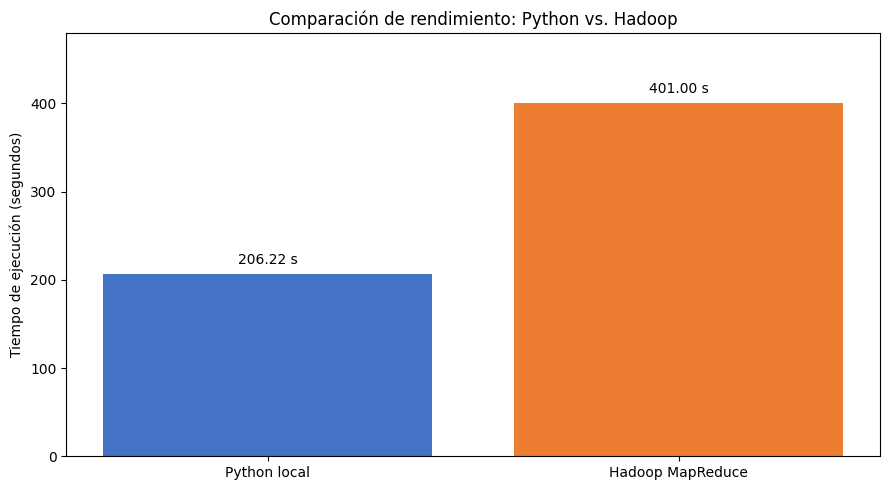

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

barras = plt.bar(
    df_rendimiento["Tecnologia"],
    df_rendimiento["Tiempo_segundos"],
    color=["#4472C4", "#ED7D31"]
)

plt.bar_label(barras, fmt="%.2f s", padding=5)

plt.title("Comparación de rendimiento: Python vs. Hadoop")
plt.ylabel("Tiempo de ejecución (segundos)")
plt.ylim(0, 480)

plt.tight_layout()

plt.savefig(
    carpeta / "comparacion_rendimiento.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

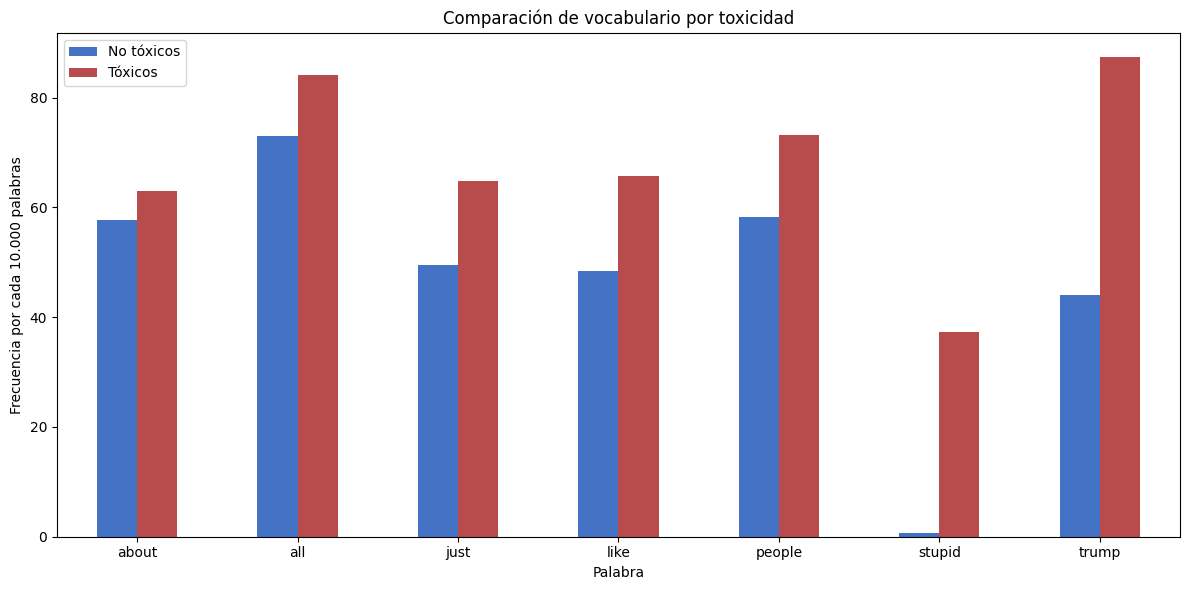

In [33]:
palabras_seleccionadas = [
    "trump", "people", "like", "all",
    "about", "just", "stupid"
]

grafica = df_palabras_full[
    df_palabras_full["palabra"].isin(
        palabras_seleccionadas
    )
].pivot(
    index="palabra",
    columns="clasificacion",
    values="frecuencia_por_10000"
).fillna(0)

grafica.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#4472C4", "#B84C4C"]
)

plt.title("Comparación de vocabulario por toxicidad")
plt.ylabel("Frecuencia por cada 10.000 palabras")
plt.xlabel("Palabra")
plt.xticks(rotation=0)
plt.legend(["No tóxicos", "Tóxicos"])

plt.tight_layout()

plt.savefig(
    carpeta / "comparacion_vocabulario.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
print("ARCHIVOS FINALES DEL TERCER CORTE\n")

for archivo in sorted(carpeta.iterdir()):
    print(archivo.name)

ARCHIVOS FINALES DEL TERCER CORTE

comparacion_rendimiento.csv
comparacion_rendimiento.png
comparacion_vocabulario.png
frecuencias_palabras.csv
mapper.py
mapreduce_full.log
prueba_local.tsv
reducer.py
resultados_mapreduce.csv
top15_por_clasificacion.csv
top20_toxicidad.csv


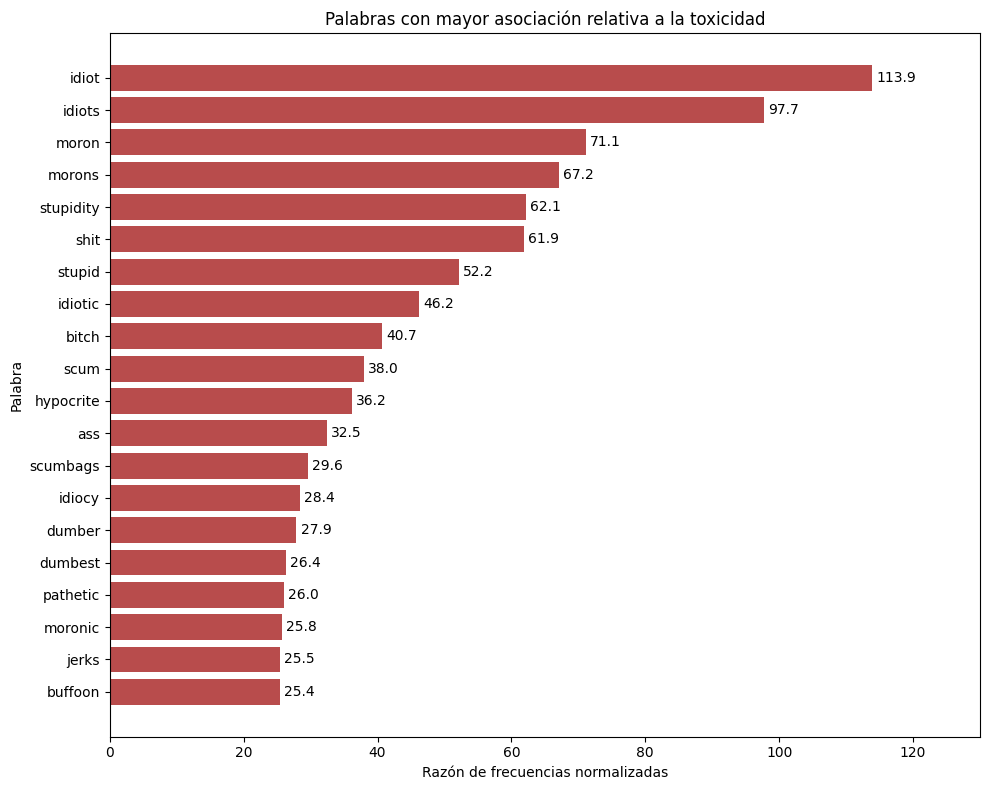

In [35]:
top20 = comparacion.nlargest(
    20, "ratio_toxicidad"
).sort_values("ratio_toxicidad")

plt.figure(figsize=(10, 8))

barras = plt.barh(
    top20.index,
    top20["ratio_toxicidad"],
    color="#B84C4C"
)

plt.bar_label(barras, fmt="%.1f", padding=3)

plt.title("Palabras con mayor asociación relativa a la toxicidad")
plt.xlabel("Razón de frecuencias normalizadas")
plt.ylabel("Palabra")
plt.xlim(0, 130)

plt.tight_layout()

plt.savefig(
    carpeta / "top20_toxicidad.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()